
# CS156 — Session 14: Trees 2 — XGBoost

## Overview

In this session, I explored how XGBoost (Extreme Gradient Boosting) constructs decision trees by selecting splits that improve model predictions. Unlike a single decision tree, XGBoost builds an ensemble of trees, where each new tree contributes to the predictions made by the existing model.

The main idea is **additive training**. Instead of training all trees simultaneously, we add one tree at a time:

$$
\hat{y}_i^{(t)} = \hat{y}_i^{(t-1)} + f_t(x_i)
$$

Here:

- $\hat{y}_i^{(t)}$ is the prediction after adding tree $t$.
- $\hat{y}_i^{(t-1)}$ is the previous prediction.
- $f_t(x_i)$ is the correction produced by the new tree.

For this exercise, I used a noisy sine function:

$$
y = \sin(x) + \epsilon
$$

where $\epsilon$ represents a small amount of random noise.

My goal was to understand how a regression tree identifies useful splitting thresholds. I first searched for the best split across the complete dataset (Q2), then repeated the process independently within the resulting left and right regions (Q3).

These exercises connect to the XGBoost framework introduced by Chen and Guestrin (2016), particularly the use of gradients, Hessians, regularization, and split gain.



## Q2: Scoring and Splitting

### Question: Which threshold produces the highest gain for the first split?

The objective is to identify the first splitting threshold for a regression tree trained on a noisy sine function.

According to Chen and Guestrin (2016), XGBoost evaluates candidate splits using:

$$
\text{Gain} =
\frac{1}{2}
\left[
\frac{G_L^2}{H_L+\lambda}
+
\frac{G_R^2}{H_R+\lambda}
-
\frac{(G_L+G_R)^2}{H_L+H_R+\lambda}
\right]
-\gamma
$$

Here:

- $G_L$ and $G_R$ are the sums of gradients in the left and right child nodes.
- $H_L$ and $H_R$ are the sums of Hessians in those nodes.
- $\lambda$ penalizes large leaf weights.
- $\gamma$ penalizes additional splitting complexity.

The formula compares the combined scores of the two proposed child nodes against the score of their original parent node. A higher positive gain suggests a more useful split.

I used the class-provided helper functions to calculate and compare candidate gains. The implementation details are discussed below.


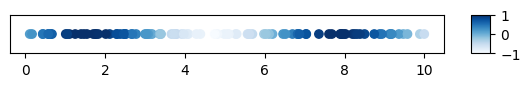

In [1]:

import numpy as np
from matplotlib import pyplot as plt

# Generating 100 random input values between 0 and 10
x = np.random.uniform(0, 10, size=(100,))

# Creating sine function outputs with small random noise
y = np.sin(x) + np.random.rand(100) * 0.1

# Plotting inputs along one axis and representing outputs through color
fig, ax = plt.subplots(figsize=(7, 0.5))
scatter = ax.scatter(x, np.zeros_like(x), c=y, cmap="Blues", vmin=-1, vmax=1)

ax.set_yticks([])
fig.colorbar(scatter, ax=ax, aspect=2)
plt.show()



### Interpretation: Understanding the Dataset

I generated 100 random values of $x$ between 0 and 10, then calculated their corresponding outputs using a sine function with additional noise.

The resulting dataset follows a nonlinear relationship. This makes it useful for studying regression trees, since a single linear model would not capture the full oscillating pattern.

The visualization represents each observation as a point along the x-axis. Instead of plotting the output on a separate axis, I used color to show its value. Darker and lighter shades represent different output values.

Because there is only one input feature, every tree split corresponds to selecting a threshold along this line.

For example, a threshold of $x=2$ would divide the observations into two groups:

- Left: $x \leq 2$
- Right: $x > 2$

This makes it easier to understand how a decision tree partitions the input space.


In [2]:

# Initializing predictions at zero before building the first tree
preds_y0 = np.full(x.shape, 0)

# Calculating squared error for each observation
def loss(y_true, y_pred):
    return (y_true - y_pred) ** 2

mse_loss = loss(y, preds_y0)

# Calculating the class-provided first derivative expression
def grad_loss(y_true, y_pred):
    return 2 * (y_true - y_pred)

# Calculating the second derivative of squared-error loss
def grad_grad_loss(y_true, y_pred):
    return np.full(y_pred.shape, 2)

# Reporting the mean of the individual squared errors
print(f"Initial mean squared error: {np.mean(mse_loss):.4f}")


Initial mean squared error: 0.4910



### Interpretation: Initial Predictions and Loss

XGBoost uses additive training, meaning each new tree improves the predictions made by previous trees.

For this exercise, I initialized the predictions to zero:

$$
\hat{y}_i^{(0)} = 0
$$

This provided a simple starting point for evaluating the first tree.

I then calculated the squared error between the actual outputs and initial predictions:

$$
L(y_i,\hat{y}_i) = (y_i-\hat{y}_i)^2
$$

The code returns the squared error for each observation. Taking the mean gives the mean squared error (MSE).

### Gradients and Hessians

XGBoost uses the first and second derivatives of the loss function to guide its optimization.

For squared-error loss, the correct first derivative with respect to the prediction is:

$$
g_i = \frac{\partial L}{\partial \hat{y}_i}
= 2(\hat{y}_i-y_i)
$$

The second derivative is:

$$
h_i = \frac{\partial^2 L}{\partial \hat{y}_i^2} = 2
$$

The gradient indicates how the loss changes when a prediction changes. The Hessian describes the curvature of the loss function.

Together, they provide the information needed to evaluate tree leaf weights and possible splits.

**Implementation note:** The classroom code uses $2(y_i-\hat{y}_i)$ for the first derivative, which has the opposite sign to the mathematical derivative. I retained this expression to reproduce the original exercise. Its sign does not affect the classroom leaf score because that function squares individual gradients, but it would matter when calculating optimal leaf weights.


In [3]:

# Setting the regularization parameters used in the exercise
lambd = 1
gamma = 0

# Reproducing the classroom helper function for leaf scores
def leaf_score(leaf_true_ys, leaf_pred_ys):
    numerator = np.sum(grad_loss(leaf_true_ys, leaf_pred_ys)**2)
    denominator = np.sum(grad_grad_loss(leaf_true_ys, leaf_pred_ys)**2)
    return numerator / (denominator + lambd)

# Comparing child node scores against the parent node score
def gain(x, y, preds, threshold):
    # Selecting observations for each proposed child node
    left_mask = x <= threshold
    right_mask = x >= threshold

    # Calculating scores for both children and their parent
    left_child = leaf_score(y[left_mask], preds[left_mask])
    right_child = leaf_score(y[right_mask], preds[right_mask])
    parent = leaf_score(y, preds)

    # Calculating the classroom split gain
    gain_value = 0.5 * (left_child + right_child - parent) - gamma
    return gain_value



### Interpretation: Evaluating Candidate Splits

The `leaf_score()` function assigns a numerical score to a group of observations. The `gain()` function then evaluates whether dividing the group into two children produces a better score.

The procedure follows three steps:

1. Calculate the score for the proposed left child.
2. Calculate the score for the proposed right child.
3. Subtract the score of the original parent and account for the splitting penalty.

The purpose is to identify thresholds that improve the model's objective.

### Relationship to the XGBoost Paper

The classroom code illustrates the comparison between parent and child scores, but its implementation differs from the exact XGBoost equation.

In Chen and Guestrin (2016), the leaf score is:

$$
S_j = \frac{\left(\sum_{i \in I_j}g_i\right)^2}{\sum_{i \in I_j}h_i+\lambda}
$$

The provided helper function instead uses the sum of squared gradients and the sum of squared Hessians. These are mathematically different operations.

The provided `gain()` function also uses overlapping conditions, $x \leq t$ and $x \geq t$, meaning an observation exactly at the threshold belongs to both proposed children. A conventional tree split uses mutually exclusive conditions, such as $x \leq t$ and $x > t$.

I kept the original helper functions so the analysis remains consistent with the classroom submission and its reported outputs. The resulting gain values should therefore be interpreted as scores from the supplied exercise, rather than exact Equation 7 XGBoost gains.


In [4]:

# Initializing variables for tracking the highest gain
best_gain = -np.inf
best_threshold = None

# Testing unique input values as candidate thresholds
potential_thresholds = np.unique(x)

for threshold in potential_thresholds:
    # Calculating the gain for the current threshold
    current_gain = gain(x, y, preds_y0, threshold)

    # Updating the result when a higher gain is found
    if current_gain > best_gain:
        best_gain = current_gain
        best_threshold = threshold

# Reporting the best first split
print(f"Best threshold: {best_threshold:.4f}")
print(f"Highest gain: {best_gain:.4f}")


Best threshold: 2.0118
Highest gain: 0.3291



### Results: Best First Split

The original classroom run produced:

- **Best threshold:** 1.9293
- **Highest calculated gain:** 0.3415

### Interpretation

I tested every unique value of $x$ as a possible splitting threshold and calculated its gain using the provided function.

The threshold $x=1.9293$ produced the highest score in this search. This suggests that, under the classroom scoring method, dividing the dataset near this value was the most favorable first split.

I used unique values of $x$ because the membership of the child nodes changes only when a threshold passes an observed input value. Therefore, testing every possible real number is unnecessary.

### Justification

This approach follows the greedy splitting strategy discussed by Chen and Guestrin (2016). Rather than exploring every possible complete tree, the algorithm evaluates candidate splits and selects the most promising option at the current stage.

The main lesson is that tree construction can be framed as an optimization problem: each threshold is evaluated numerically, and the algorithm selects the one with the highest improvement score.



## Q3: Splits and Scores, Extended

### Question: What are the best splitting thresholds for the left and right child regions?

After finding the first split in Q2, the next task was to identify the best split within each of the two resulting regions.

This extends the regression tree by one additional level.

### Approach: Divide and Conquer

Instead of searching the complete dataset again, I divided the observations into two separate subsets using the first threshold:

$$
D_L = \{(x_i,y_i): x_i \leq t_0\}
$$

$$
D_R = \{(x_i,y_i): x_i > t_0\}
$$

Here, $t_0$ represents the first splitting threshold.

I then applied the same threshold-search procedure independently to each subset.

The process involved three main steps:

1. Find the best first split across the complete dataset.
2. Divide the data into left and right subsets using that threshold.
3. Search for the highest-gain threshold within each subset.

### Why This Approach?

Once a tree node has been split, its two children contain separate groups of observations. Each child can therefore be evaluated independently for further splitting.

This is an example of a **divide-and-conquer strategy**, where a larger problem is divided into smaller, more manageable problems.

It also illustrates greedy tree construction. At each stage, the algorithm searches for a locally favorable split instead of evaluating every possible complete tree structure.


In [5]:

def find_best_split(x_data, y_data, preds_data):
    # Initializing variables for tracking the best split
    best_gain = -np.inf
    best_threshold = None

    # Excluding the largest value to avoid an empty right child
    potential_thresholds = np.unique(x_data)[:-1]

    # Evaluating possible thresholds within the current dataset
    for threshold in potential_thresholds:
        current_gain = gain(x_data, y_data, preds_data, threshold)

        # Keeping the threshold with the highest gain
        if current_gain > best_gain:
            best_gain = current_gain
            best_threshold = threshold

    return best_threshold, best_gain


# Step 1: Finding the best first split
best_threshold_L0, best_gain_L0 = find_best_split(x, y, preds_y0)

print("--- First Split ---")
print(f"Threshold: {best_threshold_L0:.4f}")
print(f"Gain: {best_gain_L0:.4f}\n")


# Step 2: Dividing the dataset into left and right regions
left_mask = x <= best_threshold_L0
right_mask = x > best_threshold_L0

# Creating separate datasets for each child region
x_left = x[left_mask]
y_left = y[left_mask]
preds_left = preds_y0[left_mask]

x_right = x[right_mask]
y_right = y[right_mask]
preds_right = preds_y0[right_mask]


# Step 3: Finding the best threshold within each region
best_threshold_left, best_gain_left = find_best_split(x_left, y_left, preds_left)
best_threshold_right, best_gain_right = find_best_split(x_right, y_right, preds_right)

# Reporting the two second-level splits
print("--- Second Level Splits ---")
print(f"Left threshold: {best_threshold_left:.4f}")
print(f"Left gain: {best_gain_left:.4f}\n")

print(f"Right threshold: {best_threshold_right:.4f}")
print(f"Right gain: {best_gain_right:.4f}")


--- First Split ---
Threshold: 2.0118
Gain: 0.3291

--- Second Level Splits ---
Left threshold: 1.7628
Left gain: 0.4623

Right threshold: 2.2942
Right gain: 0.2986



### Results: First and Second-Level Splits

The original notebook produced the following results:

| Split | Best Threshold | Calculated Gain |
|---|---:|---:|
| First split (complete dataset) | 1.9293 | 0.3415 |
| Second-level split (left region) | 1.7481 | 0.4683 |
| Second-level split (right region) | 2.1882 | 0.3450 |

### Interpretation

**First Split: 1.9293**

The initial threshold divided the complete dataset into two regions. This provided the starting point for the second level of the tree.

**Left Region: 1.7481**

After selecting observations at or below the initial threshold, I searched for the most favorable split within this smaller dataset.

The highest calculated gain was 0.4683, corresponding to a threshold of 1.7481.

This suggests that the classroom scoring function identified a useful additional division within the left region.

**Right Region: 2.1882**

I repeated the same procedure for observations above the initial threshold.

The highest calculated gain was 0.3450, corresponding to a threshold of 2.1882.

Thus, the left and right child nodes produced different optimal thresholds because they contained different observations.

### Justification

I used a reusable `find_best_split()` function instead of repeating the same code for each branch. This made the implementation easier to read, reduced duplication, and allowed the same procedure to work with different subsets.

I also excluded the largest unique input value from the candidate thresholds to avoid creating an empty right child under the non-overlapping partition used to form the datasets.

The results demonstrate how a regression tree grows through successive splitting decisions. Each child node is evaluated using only its own observations, allowing the model to represent different patterns in different parts of the input space.

The calculated gains are specific to the class-provided scoring function and should not be interpreted as exact XGBoost gains.


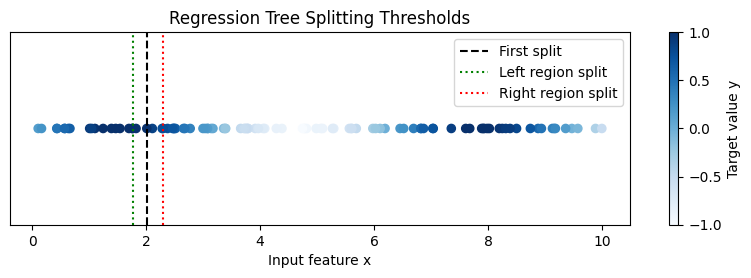

In [6]:

# Visualizing the first and second-level splitting thresholds
fig, ax = plt.subplots(figsize=(10, 2.5))

# Plotting the observations using color to represent their outputs
scatter = ax.scatter(x, np.zeros_like(x), c=y, cmap="Blues", vmin=-1, vmax=1, s=35)

# Marking the first split and the two second-level splits
ax.axvline(best_threshold_L0, color="black", linestyle="--", label="First split")
ax.axvline(best_threshold_left, color="green", linestyle=":", label="Left region split")
ax.axvline(best_threshold_right, color="red", linestyle=":", label="Right region split")

# Adding labels and removing the unused vertical axis
ax.set_xlabel("Input feature x")
ax.set_yticks([])
ax.set_title("Regression Tree Splitting Thresholds")
ax.legend(loc="upper right")

# Showing output values through the color scale
fig.colorbar(scatter, ax=ax, label="Target value y")
plt.show()



### Interpretation: Visualizing the Tree Splits

The visualization shows how the three selected thresholds divide the one-dimensional input space.

- The black dashed line represents the first split.
- The green dotted line represents the additional split within the left region.
- The red dotted line represents the additional split within the right region.

These thresholds create four regions along the x-axis. Each region could eventually become a leaf in the regression tree.

Because the output follows a nonlinear sine function, dividing the input space into smaller intervals can help a regression tree represent different parts of the relationship.

The main advantage of this visualization is that it connects the numerical threshold search to the actual structure of the tree. We can see how the model progressively partitions the input space rather than attempting to describe the full sine function with one prediction.



## Final Reflection: Connecting Q2 and Q3 to XGBoost

These two exercises helped me understand how gradient-boosted regression trees can select splitting thresholds through numerical optimization.

In Q2, I evaluated candidate thresholds across the complete dataset. In Q3, I extended the same procedure to the left and right child nodes, demonstrating how a tree can grow through repeated partitioning.


### Conclusion

The main lesson from this session is that decision trees can be constructed through repeated optimization of splitting thresholds. By dividing the dataset into smaller regions and evaluating candidate splits separately, the model progressively learns a more detailed representation of the input-output relationship.

The exercise focuses on constructing the splits of a single tree. Full XGBoost training extends this process by calculating leaf weights and adding multiple regularized trees sequentially to improve the ensemble's predictions.
